In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, xgboost, shap, imblearn

print("sklearn", sklearn.__version__)
print("xgboost", xgboost.__version__)

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

c:\Users\arnav\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sklearn 1.9.1
xgboost 3.4.1
(7043, 21)


In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Tenure of those rows:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())

Missing TotalCharges: 11
Tenure of those rows: [0]


In [3]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)

print("Nulls left:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Churn rate:", round(df["Churn"].mean(), 4))
df.dtypes

Nulls left: 0
Duplicate rows: 22
Churn rate: 0.2654


gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [4]:
import os
os.makedirs("../reports", exist_ok=True)
sns.set_theme(style="whitegrid")

def save(name):
    plt.tight_layout()
    plt.savefig(f"../reports/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

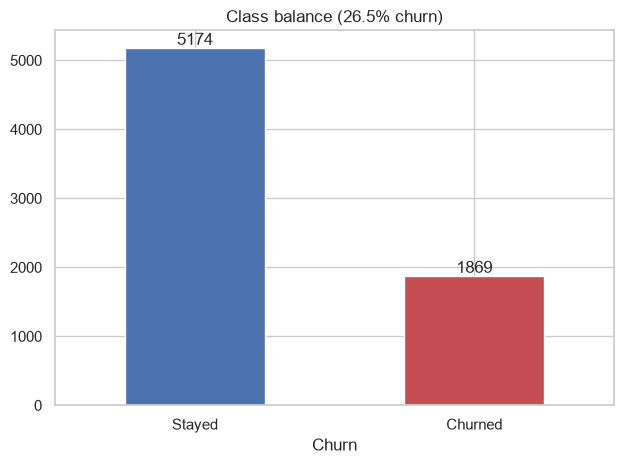

In [5]:
ax = df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(color=["#4c72b0", "#c44e52"])
ax.set_title("Class balance (26.5% churn)")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0)
save("01_class_balance")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


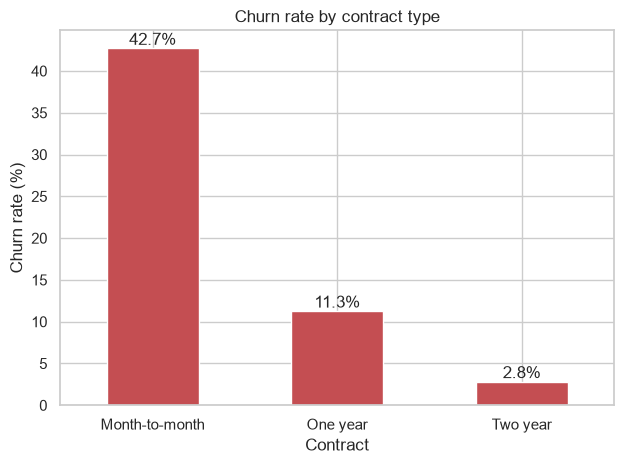

In [6]:
rate = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
print(rate.round(3))
ax = rate.mul(100).plot.bar(color="#c44e52")
ax.set_ylabel("Churn rate (%)"); ax.set_title("Churn rate by contract type")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
save("02_contract")

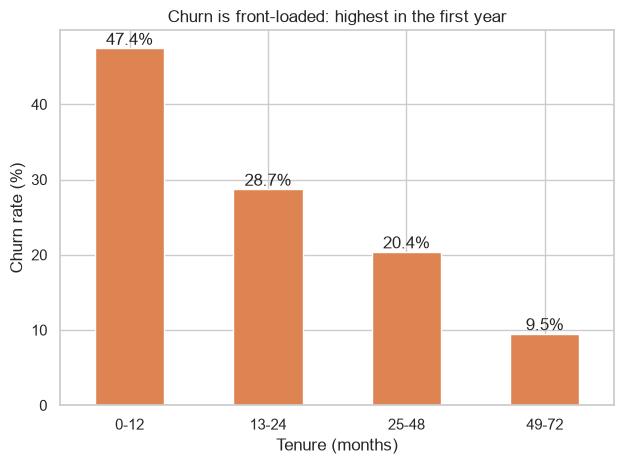

In [7]:
df["tenure_bucket"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72],
                             labels=["0-12", "13-24", "25-48", "49-72"])
rate = df.groupby("tenure_bucket", observed=True)["Churn"].mean() * 100
ax = rate.plot.bar(color="#dd8452")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Tenure (months)")
ax.set_title("Churn is front-loaded: highest in the first year")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
save("03_tenure")
df = df.drop(columns="tenure_bucket")   # helper column only; remove it

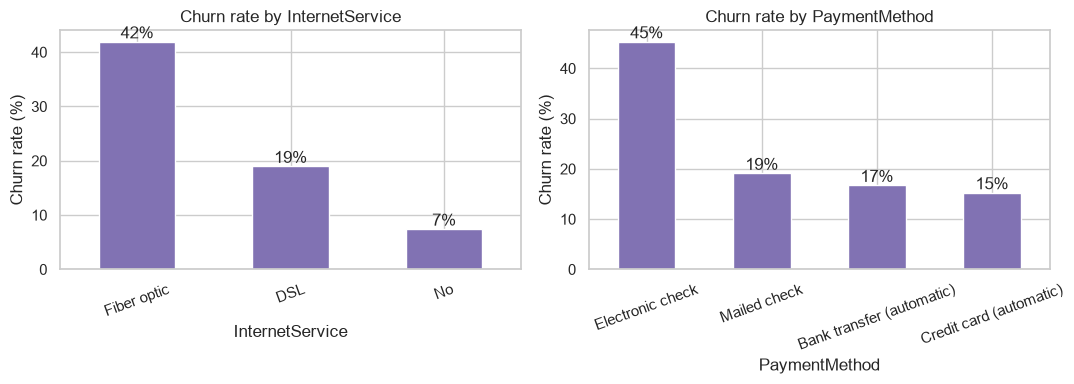

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["InternetService", "PaymentMethod"]):
    r = df.groupby(col)["Churn"].mean().mul(100).sort_values(ascending=False)
    r.plot.bar(ax=ax, color="#8172b3")
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate (%)")
    ax.bar_label(ax.containers[0], fmt="%.0f%%")
    ax.tick_params(axis="x", rotation=20)
save("04_internet_payment")

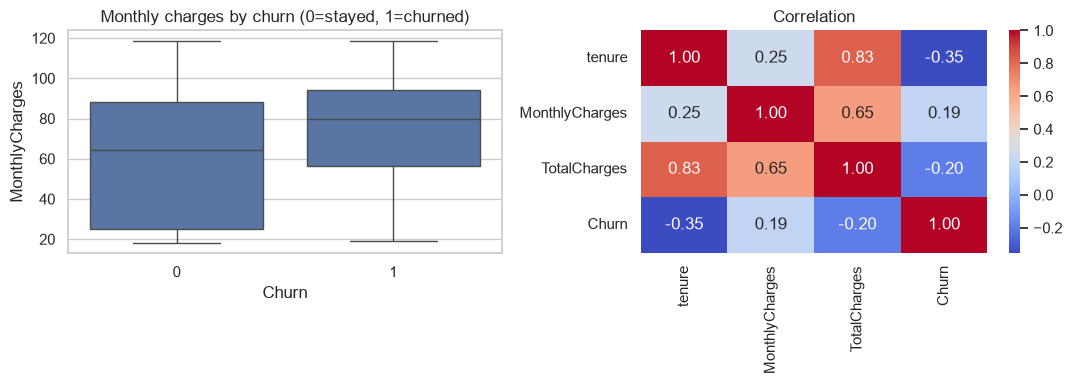

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[0])
axes[0].set_title("Monthly charges by churn (0=stayed, 1=churned)")
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlation")
save("05_charges_corr")